# 62 · Burgers

**Question.** Where does the Carleman lift converge on viscous Burgers, does the ratio R predict it, and what does a lift that fails look like?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p6_build", "p6_encode", "p6_t3")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p6_build: 374 records, 374 ok
p6_encode: 72 records, 72 ok
p6_t3: 140 records, 140 ok


In [2]:
import math
from itertools import pairwise

from IPython.display import Markdown, display

from pihm.problems import ladder

builds = [
    r
    for r in results.rows("p6_build")
    if r["status"] == "ok" and r["rung"] == "R9" and not r["label"]
]


def floors(regime):
    """Return, per problem and order, the lift's error over a at the order's finest n_t."""
    found = {}
    for r in builds:
        key = (r["problem"], r["carleman"])
        if r["regime"] == regime and (key not in found or r["n"] > found[key]["n"]):
            found[key] = r
    return {
        key: (r["lift_err_linf"] / ladder.burgers_panel(key[0])[0], r["trusted"])
        for key, r in found.items()
    }


def per_order(points):
    """Return the geometric mean of the error's ratio from one order to the next."""
    steps = [b[1] / a[1] for a, b in pairwise(sorted(points)) if b[0] == a[0] + 1]
    return math.exp(sum(math.log(s) for s in steps) / len(steps)) if steps else None


lifted = floors("descriptor")
series = {}
for strength in ladder.R9_STRENGTHS.values():
    per = {}
    for (name, order), (error, trusted) in sorted(lifted.items()):
        a, modes = ladder.burgers_panel(name)
        if a == strength:
            per.setdefault(modes, []).append((order, error, trusted))
    if per:
        series[f"a/ν = {strength:g}"] = per

lines = []
for label, per in series.items():
    rates = sorted((modes, per_order(points)) for modes, points in per.items())
    shown = ", ".join(f"{rate:.2f} on {modes} modes" for modes, rate in rates if rate)
    lines.append(f"- {label}: the lift's error changes by {shown} an order.")
trusted = sum(flag for _, flag in lifted.values())
lines.append(f"- {trusted} of {len(lifted)} of these builds are trusted, the diverging ones too.")
display(Markdown("\n".join(lines)))

- a/ν = 0.03: the lift's error changes by 0.01 on 4 modes, 0.01 on 8 modes, 0.01 on 16 modes an order.
- a/ν = 0.3: the lift's error changes by 0.06 on 4 modes, 0.05 on 8 modes, 0.06 on 16 modes an order.
- a/ν = 1: the lift's error changes by 0.19 on 4 modes, 0.18 on 8 modes, 0.20 on 16 modes an order.
- a/ν = 3: the lift's error changes by 0.56 on 4 modes, 0.52 on 8 modes, 0.57 on 16 modes an order.
- a/ν = 10: the lift's error changes by 1.75 on 4 modes, 1.74 on 8 modes, 1.40 on 16 modes an order.
- 45 of 45 of these builds are trusted, the diverging ones too.

The lift's error against its order, relative to the amplitude, at each order's finest time axis,
a line per strength and a panel per number of modes. Hollow markers are untrusted kernels.

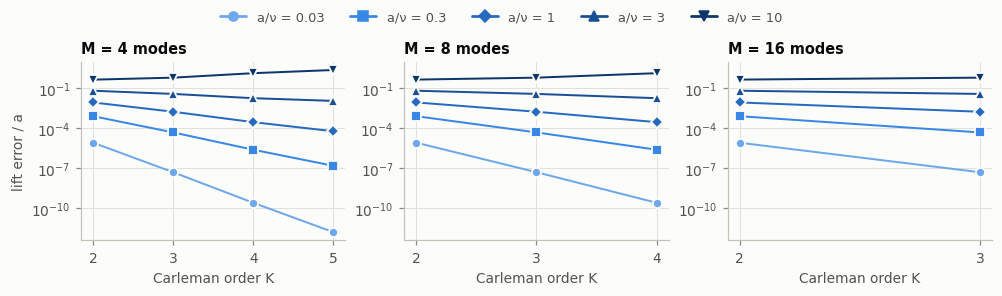

In [3]:
plotting.lift_convergence(series, "lift error / a");

The minimax filter's degree (T3) on four and eight modes at K = 3, in both forms.

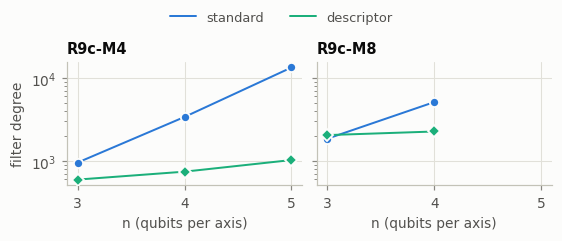

In [4]:
estimates = [
    r
    for r in results.rows("p6_t3")
    if r["status"] == "ok" and r["problem"].startswith("R9c") and r["carleman"] == 3
]
plotting.by_resolution(
    {form: [r for r in estimates if r["regime"] == form] for form in ("standard", "descriptor")},
    "degree",
    "filter degree",
);

**What this does not show.** The Galerkin truncation's own error, against Cole–Hopf. These
circuits encode the coupling as matchings; the tensor layout and its term count are notebook
70's.